<a href="https://colab.research.google.com/github/alyairawan02/publicdiscussion_analysis/blob/main/SMOTE_%26_RANDOM_FOREST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import random

# Fungsi augmentasi sederhana
def augment_text(text):
    if isinstance(text, str):
        words = text.split()
        if len(words) > 1:
            random.shuffle(words)
        return ' '.join(words)
    return text

In [ ]:
#augmentasi data positif dan negatif

import pandas as pd
# 1. Baca data awal
df = pd.read_excel('hasil_labeling_3.xlsx')

# 2. Augmentasi POSITIVE
pos_data = df[df['sent_label'].str.upper() == 'POSITIVE']
aug_pos = pos_data.sample(n=2 * len(pos_data), replace=True, random_state=42).copy()
aug_pos['cleaning'] = aug_pos['cleaning'].apply(augment_text)
aug_pos['sent_label'] = 'POSITIVE'
df_aug = pd.concat([df, aug_pos], ignore_index=True)

# 3. Augmentasi NEGATIVE dari data yang sudah diperluas
neg_data = df_aug[df_aug['sent_label'].str.upper() == 'NEGATIVE']
aug_neg = neg_data.sample(n=(1500 - len(neg_data)), replace=True, random_state=42).copy()
aug_neg['cleaning'] = aug_neg['cleaning'].apply(augment_text)
aug_neg['sent_label'] = 'NEGATIVE'

# 4. Gabung semua jadi satu
df_final = pd.concat([df_aug, aug_neg], ignore_index=True)

# 5. Cek hasil distribusi
print(df_final['sent_label'].value_counts())
print(f"\n✅ Augmentasi lengkap berhasil. Jumlah data akhir: {len(df_final)}")

sent_label
POSITIVE    1572
NEGATIVE    1500
NEUTRAL     1038
Name: count, dtype: int64

✅ Augmentasi lengkap berhasil. Jumlah data akhir: 4110


In [ ]:
print(df_final['sent_label'].value_counts())

sent_label
POSITIVE    1572
NEGATIVE    1500
NEUTRAL     1038
Name: count, dtype: int64


In [ ]:
!pip install transformers torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 100.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 80.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 50.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 34.0 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalling nvidia-nvjitlink-cu12-12.5.82:
      Successfully uninstalled nvidia-nvjitlin

In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline

# Load model IndoBERT Sentiment Analysis
model_name = "crypter70/IndoBERT-Sentiment-Analysis"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

# Buat pipeline untuk analisis sentimen
sentiment_pipe = pipeline("sentiment-analysis", model=model, tokenizer=tokenizer)

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/498M [00:00<?, ?B/s]

Device set to use cpu


In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences


# Encode label (pastikan kolom label bernama 'sent_label')
label_encoder = LabelEncoder()
df_final['encoded_label'] = label_encoder.fit_transform(df_final['sent_label'])

In [ ]:
# Membersihkan kolom 'cleaning' dari NaN atau baris kosong
df_final = df_final[df_final['stemming_data'].notna()]
df_final = df_final[df_final['stemming_data'].str.strip() != '']
df_final.loc[:, 'stemming_data'] = df_final['stemming_data'].astype(str)
df_final = df_final.reset_index(drop=True)

In [ ]:
df_final['stemming_data'] = df_final['stemming_data'].fillna('').astype(str)

In [ ]:
#tokenizing

# Tokenisasi teks
tokenizer = Tokenizer(num_words=5000, oov_token='<OOV>')
tokenizer.fit_on_texts(df_final['stemming_data'])

sequences = tokenizer.texts_to_sequences(df_final['stemming_data'])

In [ ]:
# Padding
max_len = 50  #  distribusi panjang teks
padded_sequences = pad_sequences(sequences, maxlen=max_len, padding='post', truncating='post')

In [ ]:
from tensorflow.keras.utils import to_categorical

# One-hot encoding untuk label
onehot_labels = to_categorical(df_final['encoded_label'], num_classes=3)

# 0 → [1. 0. 0.]
# 1 → [0. 1. 0.]
# 2 → [0. 0. 1.]

In [ ]:
#split data (test set & training set)
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    padded_sequences, onehot_labels,
    test_size=0.2,
    random_state=42
)

In [ ]:
#visualisasi split data
print("Shape X_train:", X_train.shape)
print("Shape X_test:", X_test.shape)
print("Shape y_train:", y_train.shape)
print("Shape y_test:", y_test.shape)

Shape X_train: (3280, 50)
Shape X_test: (821, 50)
Shape y_train: (3280, 3)
Shape y_test: (821, 3)


In [ ]:
print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])

Jumlah data training: 3280
Jumlah data testing: 821


In [ ]:
#SMOTE

from imblearn.over_sampling import SMOTE
from tensorflow.keras.utils import to_categorical
import numpy as np

# 1. Ubah label dari one-hot ke label integer dulu
y_train_labels = np.argmax(y_train, axis=1)

# 2. Terapkan SMOTE
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled_labels = smote.fit_resample(X_train, y_train_labels)

# 3. Kembalikan hasil SMOTE ke one-hot encoding
y_train_resampled = to_categorical(y_train_resampled_labels, num_classes=3)

# 4. Cek hasil
print("Shape X_train_resampled:", X_train_resampled.shape)
print("Shape y_train_resampled:", y_train_resampled.shape)

Shape X_train_resampled: (3849, 50)
Shape y_train_resampled: (3849, 3)


In [ ]:
import numpy as np

# mengubah one-hot encoded labels ke bentuk integer
y_test_labels = np.argmax(y_test, axis=1)
y_pred_labels = np.argmax(y_pred, axis=1) if len(y_pred.shape) > 1 else y_pred

In [ ]:
#random forest
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Inisialisasi model Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# Latih model dengan data hasil SMOTE
rf_model.fit(X_train_resampled, y_train_resampled)

# Prediksi
y_pred = rf_model.predict(X_test)

# Evaluasi
print("Confusion Matrix:")
print(confusion_matrix(y_test_labels, y_pred_labels))

print("\nClassification Report:")
print(classification_report(y_test_labels, y_pred_labels))

print("\nAccuracy Score:")
print(f"{accuracy_score(y_test_labels, y_pred_labels):.4f}")

Confusion Matrix:
[[305  28   2]
 [ 79 120   7]
 [ 11   6 263]]

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.91      0.84       335
           1       0.78      0.58      0.67       206
           2       0.97      0.94      0.95       280

    accuracy                           0.84       821
   macro avg       0.84      0.81      0.82       821
weighted avg       0.84      0.84      0.83       821


Accuracy Score:
0.8380


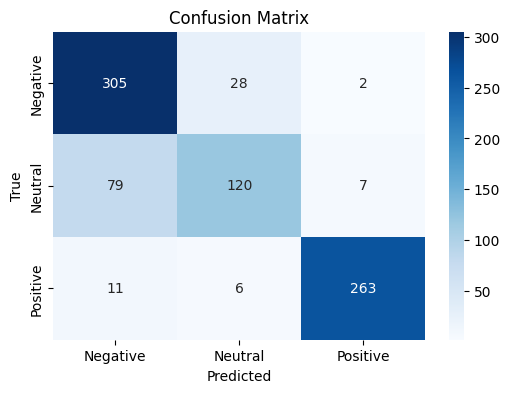

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Kalau y_test dan y_pred masih one-hot
y_test_labels = np.argmax(y_test, axis=1) if len(y_test.shape) > 1 else y_test
y_pred_labels = np.argmax(y_pred, axis=1) if len(y_pred.shape) > 1 else y_pred

# Hitung confusion matrix
cm = confusion_matrix(y_test_labels, y_pred_labels)

# Plot confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negative', 'Neutral', 'Positive'],
            yticklabels=['Negative', 'Neutral', 'Positive'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()
